# 00 · Data overview

Before any modelling: what is in the IEEE-CIS (Vesta) data, how much of it is missing and why, how the variables are distributed, and how the unlabelled test period differs from the labelled one.

Column meanings and the label definition are summarised in [`docs/data_dictionary.md`](../docs/data_dictionary.md). All logic lives in `src/fraud/profiling.py`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fraud.data import RAW_DIR, SECONDS_PER_DAY, TARGET, load_dataset
from fraud.profiling import column_group, compare_splits, group_summary, missing_blocks, missing_vs_target, segment_rates

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 30)

## 1. Files and keys

In [2]:
train = load_dataset("train")
test = load_dataset("test")
ids = {s: pd.read_csv(RAW_DIR / f"{s}_identity.csv", usecols=["TransactionID"]).TransactionID for s in ["train", "test"]}

files = pd.DataFrame([
    {
        "file": f.name,
        "size_mb": round(f.stat().st_size / 1e6),
        "columns": len(pd.read_csv(f, nrows=0).columns),
    }
    for f in sorted(RAW_DIR.glob("*.csv"))
]).set_index("file")
files["rows"] = files.index.map({
    "train_transaction.csv": len(train), "train_identity.csv": len(ids["train"]),
    "test_transaction.csv": len(test), "test_identity.csv": len(ids["test"]),
    "sample_submission.csv": len(test),
})
display(files)

for split, tx in [("train", train), ("test", test)]:
    print(f"{split}: TransactionID unique={tx.TransactionID.is_unique}, "
          f"rows with an identity record={tx.TransactionID.isin(ids[split]).mean():.1%}, "
          f"identity IDs missing from transactions={(~ids[split].isin(tx.TransactionID)).sum()}")

,size_mb,columns,rows
file,,,
sample_submission.csv,6,2,506691
test_identity.csv,26,41,141907
test_transaction.csv,613,393,506691
train_identity.csv,27,41,144233
train_transaction.csv,683,394,590540


train: TransactionID unique=True, rows with an identity record=24.4%, identity IDs missing from transactions=0
test: TransactionID unique=True, rows with an identity record=28.0%, identity IDs missing from transactions=0


Only about a quarter of transactions have device and network information, so identity must be **left-joined**. `sample_submission.csv` is the Kaggle submission template (every value 0.5) and is not used.

## 2. Time coverage

`TransactionDT` is seconds from an unpublished reference point, not a timestamp.

train: days 1-183, 27 weeks
test: days 213-396, 27 weeks
gap between train and test: 30 days


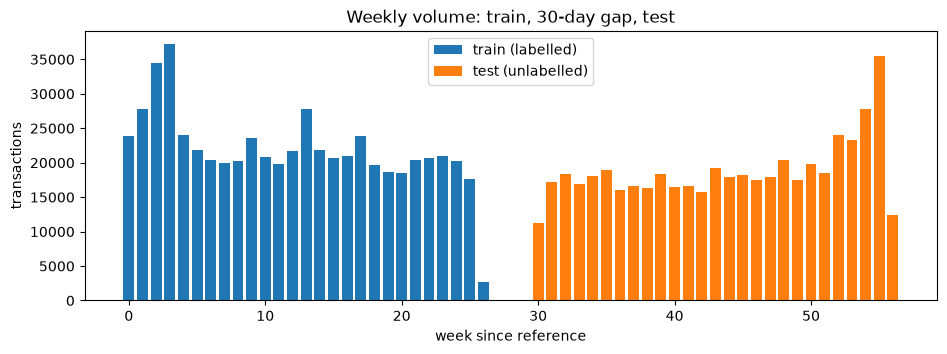

In [3]:
for split, tx in [("train", train), ("test", test)]:
    print(f"{split}: days {tx.TransactionDT.min() / SECONDS_PER_DAY:.0f}-{tx.TransactionDT.max() / SECONDS_PER_DAY:.0f}, "
          f"{tx.week.nunique()} weeks")
print(f"gap between train and test: {(test.TransactionDT.min() - train.TransactionDT.max()) / SECONDS_PER_DAY:.0f} days")

fig, ax = plt.subplots(figsize=(11, 3.5))
for split, tx, color in [("train (labelled)", train, "C0"), ("test (unlabelled)", test, "C1")]:
    weekly = tx.groupby("week").size()
    ax.bar(weekly.index, weekly.values, color=color, label=split)
ax.set(xlabel="week since reference", ylabel="transactions", title="Weekly volume: train, 30-day gap, test")
ax.legend()
fig.savefig(FIG_DIR / "00_weekly_volume.png", dpi=120, bbox_inches="tight")

## 3. Column families

In [4]:
raw_columns = [c for c in train.columns if c not in ("timestamp", "day", "week", "month", "entity_key")]
group_summary(train, raw_columns).round(3)

,n_cols,n_categorical,miss_min,miss_median,miss_max,nunique_median,nunique_max
group,,,,,,,
TransactionID,1,0,0.000,0.000,0.000,590540.0,590540
isFraud,1,0,0.000,0.000,0.000,2.0,2
TransactionDT,1,0,0.000,0.000,0.000,573349.0,573349
TransactionAmt,1,0,0.000,0.000,0.000,20902.0,20902
ProductCD,1,1,0.000,0.000,0.000,5.0,5
card1-6,6,2,0.000,0.003,0.015,116.5,13553
addr1-2,2,0,0.111,0.111,0.111,203.0,332
dist1-2,2,0,0.597,0.766,0.936,2201.0,2651
P_emaildomain,1,1,0.160,0.160,0.160,59.0,59


`n_categorical` counts columns stored as text. Several numeric-coded columns are categorical in meaning: `card1`–`card3`, `card5`, `addr1`, `addr2` (codes, not quantities), and `card1` alone has over 13k values.

## 4. Target

In [5]:
y = train[TARGET]
amt = train.TransactionAmt.astype(float)
print(f"fraud: {y.sum():,} of {len(y):,} = {y.mean():.3%} (1 in {1 / y.mean():.0f})")
print(f"fraud share of dollar volume: {amt[y == 1].sum() / amt.sum():.2%}")
print(f"median amount: fraud ${amt[y == 1].median():.2f}, legitimate ${amt[y == 0].median():.2f}")

fraud: 20,663 of 590,540 = 3.499% (1 in 29)
fraud share of dollar volume: 3.87%
median amount: fraud $75.00, legitimate $68.50


## 5. Missing data

Missingness is heavy, structured, and informative.

In [6]:
n_missing = train[raw_columns].isna().sum(axis=1)
print(f"missing cells per row (of {len(raw_columns)}): median {n_missing.median():.0f}, 10%-90% {n_missing.quantile(.1):.0f}-{n_missing.quantile(.9):.0f}")

V = [c for c in raw_columns if column_group(c) == "V1-V339"]
v_blocks = missing_blocks(train, V)
print(f"{len(V)} V columns are missing together in {len(v_blocks)} blocks")
v_blocks.drop(columns="columns").round(4)

missing cells per row (of 434): median 211, 10%-90% 109-232


339 V columns are missing together in 14 blocks


,n_cols,missing_rate,first,last
0,32,0.0000,V279,V321
1,43,0.0005,V95,V137
2,11,0.0021,V281,V315
3,23,0.1288,V12,V34
4,22,0.1306,V53,V74
5,20,0.1510,V75,V94
6,18,0.2861,V35,V52
7,11,0.4729,V1,V11
8,16,0.7605,V220,V272
9,19,0.7632,V169,V210


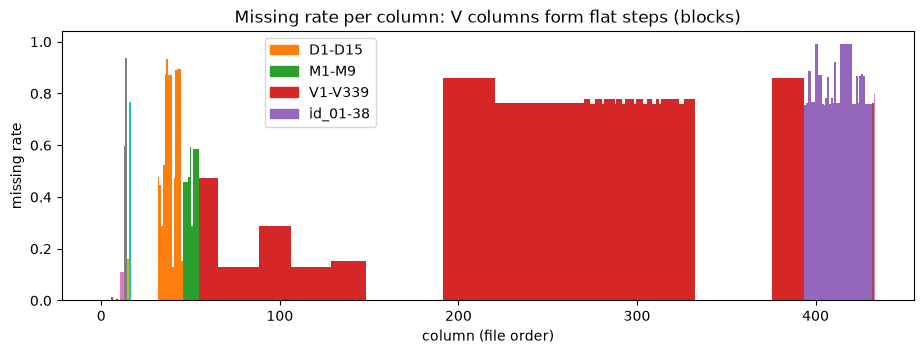

In [7]:
fig, ax = plt.subplots(figsize=(11, 3.5))
miss = train[raw_columns].isna().mean()
colors = {g: f"C{i}" for i, g in enumerate(dict.fromkeys(column_group(c) for c in raw_columns))}
ax.bar(range(len(miss)), miss.values, color=[colors[column_group(c)] for c in miss.index], width=1.0)
ax.set(xlabel="column (file order)", ylabel="missing rate", title="Missing rate per column: V columns form flat steps (blocks)")
families = ["D1-D15", "M1-M9", "V1-V339", "id_01-38"]
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=colors[g]) for g in families], labels=families, loc="upper left", bbox_to_anchor=(0.23, 1.0))
fig.savefig(FIG_DIR / "00_missing_rates.png", dpi=120, bbox_inches="tight")

In [8]:
# Is missingness itself a fraud signal?
selected = ["addr1", "dist1", "P_emaildomain", "R_emaildomain", "D2", "D8", "M4", "id_01", "DeviceInfo", "V1", "V138"]
mvt = missing_vs_target(train, selected)
mvt["ratio"] = mvt["fraud_if_missing"] / mvt["fraud_if_present"]
mvt.round(4)

,missing_rate,fraud_if_missing,fraud_if_present,ratio
column,,,,
addr1,0.1113,0.1178,0.0246,4.7850
dist1,0.5965,0.0452,0.0200,2.2628
P_emaildomain,0.1599,0.0295,0.0360,0.8198
R_emaildomain,0.7675,0.0208,0.0818,0.2546
D2,0.4755,0.0456,0.0254,1.7931
D8,0.8731,0.0249,0.1045,0.2383
M4,0.4766,0.0186,0.0499,0.3719
id_01,0.7558,0.0209,0.0785,0.2668
DeviceInfo,0.7991,0.0255,0.0725,0.3523


## 6. Distributions

TransactionAmt quantiles: {0.0: 0.25, 0.01: 9.24, 0.25: 43.32, 0.5: 68.77, 0.75: 125.0, 0.99: 1104.0, 0.999: 2769.81, 1.0: 31937.39}
skew 14.4 -> after log1p 0.49; whole-dollar amounts 51.8%


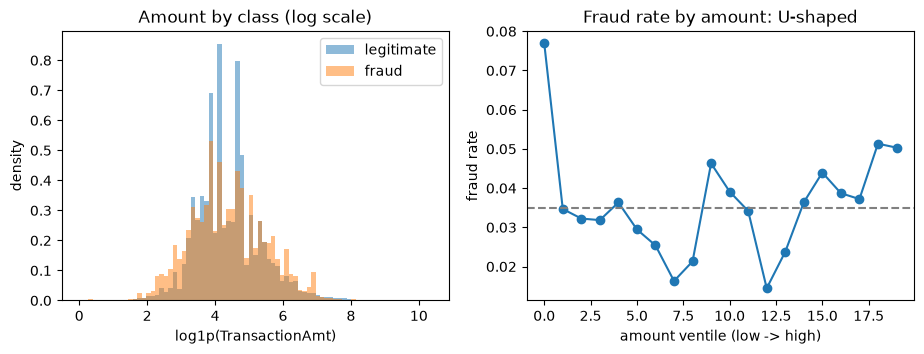

In [9]:
print("TransactionAmt quantiles:", amt.quantile([0, .01, .25, .5, .75, .99, .999, 1]).round(2).to_dict())
print(f"skew {amt.skew():.1f} -> after log1p {np.log1p(amt).skew():.2f}; whole-dollar amounts {(amt.round(2) % 1 == 0).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
bins = np.linspace(0, np.log1p(amt.max()), 80)
for label, mask in [("legitimate", y == 0), ("fraud", y == 1)]:
    axes[0].hist(np.log1p(amt[mask]), bins=bins, density=True, alpha=0.5, label=label)
axes[0].set(xlabel="log1p(TransactionAmt)", ylabel="density", title="Amount by class (log scale)")
axes[0].legend()
rate = train.groupby(pd.qcut(amt, 20, duplicates="drop"), observed=True)[TARGET].mean()
axes[1].plot(range(len(rate)), rate.values, marker="o")
axes[1].axhline(y.mean(), color="gray", ls="--")
axes[1].set(xlabel="amount ventile (low -> high)", ylabel="fraud rate", title="Fraud rate by amount: U-shaped")
fig.savefig(FIG_DIR / "00_amount.png", dpi=120, bbox_inches="tight")

In [10]:
def describe_counts(cols):
    return pd.DataFrame({
        c: {"missing": train[c].isna().mean(), "zero": (train[c] == 0).mean(), "negative": (train[c] < 0).mean(),
            "min": train[c].min(), "median": train[c].median(), "p99": train[c].quantile(.99), "max": train[c].max()}
        for c in cols
    })

print("C1-C14: counts with extreme tails")
display(describe_counts([f"C{i}" for i in range(1, 15)]).round(3))
print("D1-D15: time deltas in days")
display(describe_counts([f"D{i}" for i in range(1, 16)]).round(3))

C1-C14: counts with extreme tails


,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14
missing,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.00,0.000
zero,0.001,0.001,0.996,0.765,0.631,0.083,0.886,0.758,0.311,0.768,0.003,0.828,0.06,0.061
negative,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.00,0.000
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.00,0.000
median,1.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,1.000,0.000,1.000,0.000,3.00,1.000
p99,164.000,154.000,0.000,6.000,149.000,118.000,4.000,11.000,95.000,15.000,122.000,5.000,578.00,128.000
max,4685.000,5691.000,26.000,2253.000,349.000,2253.000,2255.000,3331.000,210.000,3257.000,3188.000,3188.000,2918.00,1429.000


D1-D15: time deltas in days


,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10,D11,D12,D13,D14,D15
missing,0.002,0.475,0.445,0.286,0.525,0.876,0.934,0.873,0.873,0.129,0.473,0.890,0.895,0.895,0.151
zero,0.474,0.026,0.124,0.282,0.111,0.078,0.036,0.001,0.007,0.376,0.190,0.072,0.083,0.077,0.295
negative,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
min,0.000,0.000,0.000,-122.000,0.000,-83.000,0.000,0.000,0.000,0.000,-53.000,-83.000,0.000,-193.000,-83.000
median,3.000,97.000,8.000,26.000,10.000,0.000,0.000,37.875,0.667,15.000,43.000,0.000,0.000,0.000,52.000
p99,602.000,617.000,356.000,623.000,455.000,593.000,429.000,983.927,0.958,622.000,609.000,514.000,371.490,562.000,635.000
max,640.000,640.000,819.000,869.000,819.000,873.000,843.000,1707.792,0.958,876.000,670.000,648.000,847.000,878.000,879.000


In [11]:
for col in ["ProductCD", "card4", "card6", "DeviceType", "P_emaildomain", "M4"]:
    print(f"{col} ({train[col].nunique()} values)")
    display(segment_rates(train, col, top=8).round(4))

ProductCD (5 values)


,n,share,fraud_rate
ProductCD,,,
W,439670,0.7445,0.0204
C,68519,0.1160,0.1169
R,37699,0.0638,0.0378
H,33024,0.0559,0.0477
S,11628,0.0197,0.0590


card4 (4 values)


,n,share,fraud_rate
card4,,,
visa,384767,0.6516,0.0348
mastercard,189217,0.3204,0.0343
american express,8328,0.0141,0.0287
discover,6651,0.0113,0.0773
NaN,1577,0.0027,0.0260


card6 (4 values)


...

,n,share,fraud_rate
DeviceType,,,
NaN,449730,0.7616,0.0210
desktop,85165,0.1442,0.0652
mobile,55645,0.0942,0.1017


P_emaildomain (59 values)


,n,share,fraud_rate
P_emaildomain,,,
gmail.com,228355,0.3867,0.0435
yahoo.com,100934,0.1709,0.0228
NaN,94456,0.1599,0.0295
hotmail.com,45250,0.0766,0.0530
anonymous.com,36998,0.0627,0.0232
aol.com,28289,0.0479,0.0218
comcast.net,7888,0.0134,0.0312
icloud.com,6267,0.0106,0.0314


M4 (3 values)


,n,share,fraud_rate
M4,,,
NaN,281444,0.4766,0.0186
M0,196405,0.3326,0.0366
M2,59865,0.1014,0.1137
M1,52826,0.0895,0.0271


## 7. Train vs test

The test period is unlabelled, but its inputs can be compared with train. This is the drift a monitor would see before any chargeback arrives.

In [12]:
pd.DataFrame({
    "train": train.ProductCD.value_counts(normalize=True),
    "test": test.ProductCD.value_counts(normalize=True),
}).round(3).T

ProductCD,W,C,R,H,S
train,0.745,0.116,0.064,0.056,0.020
test,0.712,0.137,0.070,0.058,0.023


In [13]:
inputs = [c for c in raw_columns if c not in ("TransactionID", TARGET, "TransactionDT")]
compare = compare_splits(train, test, inputs, as_categorical=["card1", "card2", "card3", "card5", "addr1", "addr2"])
print("Largest changes in missing rate")
display(compare.reindex(compare["miss_diff"].abs().sort_values(ascending=False).index).head(10).round(3))
print("Categorical columns with the most unseen values in test")
display(compare.dropna(subset=["unseen_share"]).sort_values("unseen_share", ascending=False).head(8).round(3))

Largest changes in missing rate


,miss_ref,miss_cur,miss_diff,unseen_share
column,,,,
D13,0.895,0.756,-0.139,NaN
V41,0.286,0.152,-0.134,NaN
V40,0.286,0.152,-0.134,NaN
V39,0.286,0.152,-0.134,NaN
V38,0.286,0.152,-0.134,NaN
V37,0.286,0.152,-0.134,NaN
V36,0.286,0.152,-0.134,NaN
V35,0.286,0.152,-0.134,NaN
V42,0.286,0.152,-0.134,NaN


Categorical columns with the most unseen values in test


,miss_ref,miss_cur,miss_diff,unseen_share
column,,,,
id_31,0.762,0.730,-0.032,0.606
id_30,0.869,0.861,-0.008,0.242
DeviceInfo,0.799,0.773,-0.026,0.138
card1,0.000,0.000,0.000,0.018
id_33,0.876,0.861,-0.015,0.018
addr1,0.111,0.129,0.018,0.000
card2,0.015,0.017,0.002,0.000
card5,0.007,0.009,0.002,0.000


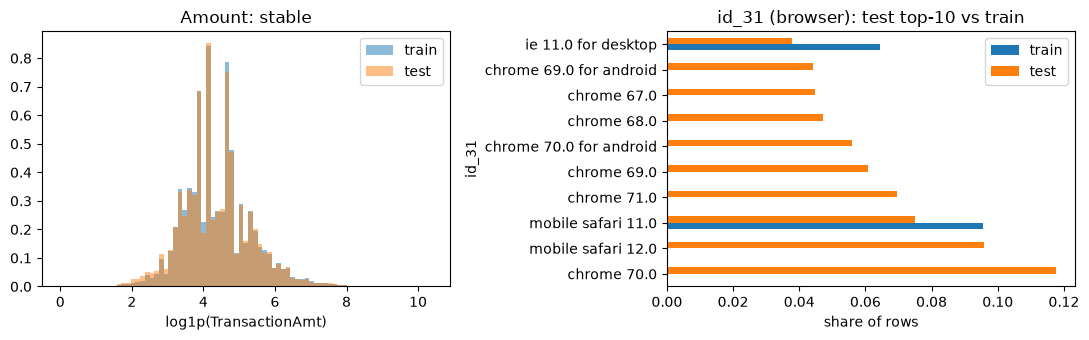

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for split, tx in [("train", train), ("test", test)]:
    axes[0].hist(np.log1p(tx.TransactionAmt.astype(float)), bins=bins, density=True, alpha=0.5, label=split)
axes[0].set(xlabel="log1p(TransactionAmt)", title="Amount: stable")
axes[0].legend()
top = test.id_31.value_counts().head(10).index
pd.DataFrame({
    "train": train.id_31.astype(str).value_counts(normalize=True).reindex(top.astype(str)),
    "test": test.id_31.value_counts(normalize=True).reindex(top).set_axis(top.astype(str)),
}).fillna(0).plot.barh(ax=axes[1])
axes[1].set(title="id_31 (browser): test top-10 vs train", xlabel="share of rows")
fig.tight_layout()
fig.savefig(FIG_DIR / "00_train_vs_test.png", dpi=120, bbox_inches="tight")

## Findings and what they imply

See `docs/data_dictionary.md` for the full write-up. In short:

1. **Missingness is a signal, not noise.** Keep NaN (LightGBM routes it); never impute without a missing flag.
2. **339 V columns = 14 missing-together blocks.** Monitor null rates per block, not per column.
3. **Several numeric columns are categorical codes** (`card1`, `addr1`, …): use JS divergence on values, not binned PSI, when monitoring them.
4. **Labels mature over 120 days** and spread to linked accounts: label delay in M5 should be tested beyond 4 weeks.
5. **The test period already shows drift**: new browser and OS versions, a whole V block changing its missing rate, a shift towards the high-fraud product C, and a seasonal volume spike. M4 can monitor real drift, not only injected drift.